<a href="https://colab.research.google.com/github/Ahmettufan3310/74-musteri-segmentasyonu-rfm/blob/main/notebooks/07_segment_gecisi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install ucimlrepo -q
from ucimlrepo import fetch_ucirepo
import pandas as pd

df = fetch_ucirepo(id=352).data.original

temiz = df.dropna(subset=['CustomerID'])
temiz = temiz[~temiz['InvoiceNo'].astype(str).str.startswith('C')]
temiz = temiz[(temiz['Quantity'] > 0) & (temiz['UnitPrice'] > 0)]

cikar = ['POST', 'M', 'C2', 'DOT', 'BANK CHARGES', 'PADS']
temiz = temiz[~temiz['StockCode'].astype(str).isin(cikar)]

hatali = [('581483', '23843'), ('541431', '23166'), ('540815', '21108'), ('556444', '22502')]
for fatura, urun in hatali:
    temiz = temiz[~((temiz['InvoiceNo'].astype(str) == fatura) & (temiz['StockCode'].astype(str) == urun))]

temiz = temiz.drop_duplicates()
temiz['InvoiceDate'] = pd.to_datetime(temiz['InvoiceDate'])
temiz['Tutar'] = temiz['Quantity'] * temiz['UnitPrice']
print(len(temiz), temiz['CustomerID'].nunique())

391146 4333


In [2]:
ayrim = pd.Timestamp('2011-06-01')
d1 = temiz[temiz['InvoiceDate'] < ayrim]
d2 = temiz[temiz['InvoiceDate'] >= ayrim]

print("1. dönem müşteri:", d1['CustomerID'].nunique())
print("2. dönem müşteri:", d2['CustomerID'].nunique())

1. dönem müşteri: 2715
2. dönem müşteri: 3540


In [3]:
def rfm_hesapla(veri):
    ref = veri['InvoiceDate'].max() + pd.Timedelta(days=1)
    return veri.groupby('CustomerID').agg(
        Recency=('InvoiceDate', lambda x: (ref - x.max()).days),
        Frequency=('InvoiceNo', 'nunique'),
        Monetary=('Tutar', 'sum')
    ).reset_index()

rfm1 = rfm_hesapla(d1)
rfm2 = rfm_hesapla(d2)
print(rfm1.shape, rfm2.shape)

(2715, 4) (3540, 4)


In [4]:
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

cols = ['Recency', 'Frequency', 'Monetary']

olcekleyici = StandardScaler()
X1 = olcekleyici.fit_transform(np.log1p(rfm1[cols]))
X2 = olcekleyici.transform(np.log1p(rfm2[cols]))

km = KMeans(n_clusters=4, random_state=42, n_init=10)
rfm1['Kume'] = km.fit_predict(X1)
rfm2['Kume'] = km.predict(X2)

In [9]:
ozet = rfm1.groupby('Kume')[cols].median()
print(ozet)

vip = ozet['Monetary'].idxmax()
uykuda = ozet.drop(vip)['Recency'].idxmax()
kalan = ozet.drop([vip, uykuda])
sadik = kalan['Monetary'].idxmax()
yeni = kalan['Monetary'].idxmin()

isim = {vip: 'VIP', sadik: 'Sadık', yeni: 'Yeni/Potansiyel', uykuda: 'Uykuda'}
rfm1['Segment'] = rfm1['Kume'].map(isim)
rfm2['Segment'] = rfm2['Kume'].map(isim)
print(isim)

      Recency  Frequency  Monetary
Kume                              
0        14.0        2.0    468.77
1        55.0        2.0    901.49
2        97.0        1.0    230.25
3        13.0        7.0   2503.78
{np.int32(3): 'VIP', np.int32(1): 'Sadık', np.int32(0): 'Yeni/Potansiyel', np.int32(2): 'Uykuda'}


In [10]:
gecis = rfm1[['CustomerID', 'Segment']].merge(
    rfm2[['CustomerID', 'Segment']], on='CustomerID', how='left', suffixes=('_1', '_2'))
gecis['Segment_2'] = gecis['Segment_2'].fillna('Alışveriş yok')

sira1 = ['VIP', 'Sadık', 'Yeni/Potansiyel', 'Uykuda']
sira2 = sira1 + ['Alışveriş yok']

tablo = pd.crosstab(gecis['Segment_1'], gecis['Segment_2'], normalize='index') * 100
tablo = tablo.reindex(index=sira1, columns=sira2, fill_value=0).round(1)
print(tablo)

yeni_gelen = len(set(rfm2['CustomerID']) - set(rfm1['CustomerID']))
print("2. dönemde ilk kez gelen müşteri:", yeni_gelen)

Segment_2         VIP  Sadık  Yeni/Potansiyel  Uykuda  Alışveriş yok
Segment_1                                                           
VIP              72.6   16.5              4.1     3.9            2.8
Sadık            22.1   32.7             14.4    12.3           18.6
Yeni/Potansiyel  10.7   23.0             19.5    23.1           23.7
Uykuda            4.6   12.9             14.4    20.8           47.2
2. dönemde ilk kez gelen müşteri: 1618


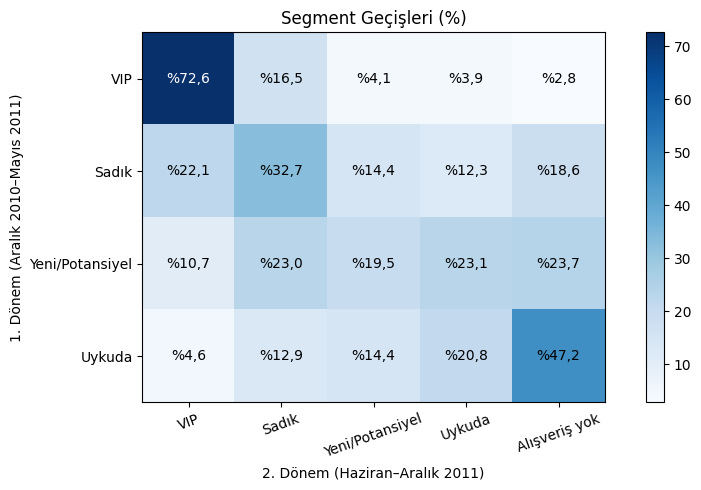

In [11]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 5))
im = ax.imshow(tablo.values, cmap='Blues')
ax.set_xticks(range(len(sira2)))
ax.set_xticklabels(sira2, rotation=20)
ax.set_yticks(range(len(sira1)))
ax.set_yticklabels(sira1)

for i in range(len(sira1)):
    for j in range(len(sira2)):
        v = tablo.values[i, j]
        ax.text(j, i, f'%{v:.1f}'.replace('.', ','), ha='center', va='center',
                color='white' if v > 50 else 'black')

ax.set_xlabel('2. Dönem (Haziran–Aralık 2011)')
ax.set_ylabel('1. Dönem (Aralık 2010–Mayıs 2011)')
ax.set_title('Segment Geçişleri (%)')
plt.colorbar(im)
plt.tight_layout()
plt.show()

In [12]:
gecis.to_csv('segment_gecisleri.csv', index=False)
tablo.to_csv('gecis_matrisi.csv')
print("Kaydedildi")

Kaydedildi
